In [29]:
import numpy as np
from scipy.linalg import eigh
from numpy.linalg import svdvals
import matplotlib.pyplot as plt

Tmin, Tmax = 0.1, 50
ximin, ximax = 0.1, 100.0
N = 500

t = np.linspace(Tmin, Tmax, N)
dt = (Tmax - Tmin) / (N - 1)

w = np.ones(N) * dt
w[0] *= 0.5
w[-1] *= 0.5

Tsum = t[:,None] + t[None,:]

K = (np.exp(-ximin * Tsum) - np.exp(-ximax * Tsum)) / Tsum

Wsqrt = np.sqrt(w)
B = Wsqrt[:, None] * K * Wsqrt[None, :]

lam = eigh(B, eigvals_only=True)
lam = lam[::-1]
lam = lam[lam > 1e-14]

sigma = np.sqrt(lam)

In [30]:
sigma, v = eigh(B)

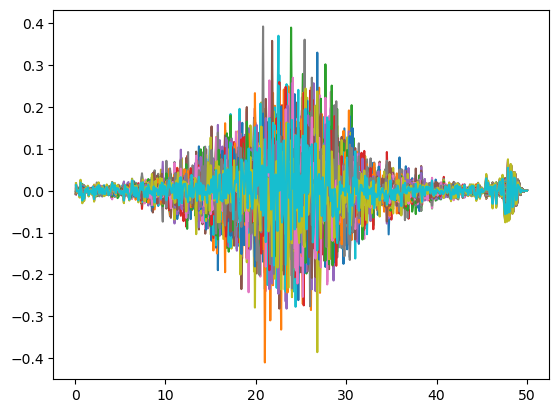

In [31]:
for i in range(450, 500):
    plt.plot(np.linspace(Tmin, Tmax, N), v[i,:])

A = 2.485480
beta = 0.771976
R² = 0.999966


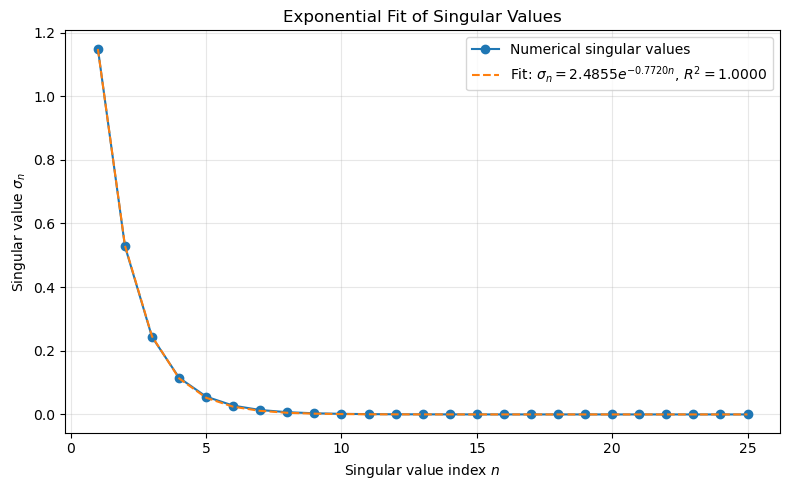

In [12]:
from scipy.optimize import curve_fit

n = np.arange(1, len(sigma) + 1)

# Exponential model
def exp_model(n, A, beta):
    return A * np.exp(-beta * n)

# Fit directly to singular values (not their logarithms)
popt, pcov = curve_fit(
    exp_model, n, sigma,
    p0=[sigma[0], 0.5],
    bounds=(0, np.inf)
)

A, beta = popt
sigma_fit = exp_model(n, A, beta)

# R-squared on linear scale
ss_res = np.sum((sigma - sigma_fit)**2)
ss_tot = np.sum((sigma - np.mean(sigma))**2)
r2 = 1 - ss_res / ss_tot

print(f"A = {A:.6f}")
print(f"beta = {beta:.6f}")
print(f"R² = {r2:.6f}")

# Plot on linear scale
plt.figure(figsize=(8, 5))
plt.plot(n, sigma, 'o-', label="Numerical singular values")
plt.plot(
    n, sigma_fit, '--',
    label=rf"Fit: $\sigma_n={A:.4f}e^{{-{beta:.4f}n}}$, $R^2={r2:.4f}$"
)

plt.xlabel("Singular value index $n$")
plt.ylabel(r"Singular value $\sigma_n$")
plt.title("Exponential Fit of Singular Values")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

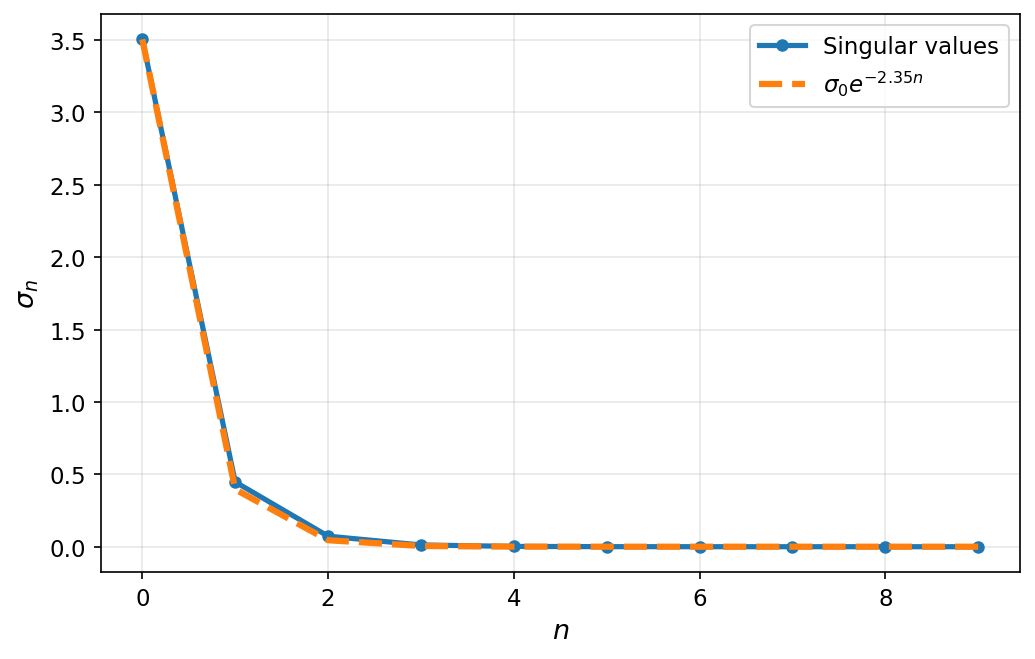

In [30]:
sigma_space = np.arange(len(sigma))
n_linspace = np.linspace(0, len(sigma), 100)
    
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

# Singular values
ax.plot(
    sigma_space,
    sigma,
    'o-',
    linewidth=2.5,
    markersize=5,
    label='Singular values'
)

# Exponential fit
a = sigma[0]
b = -2.18
exp_fit = a * np.exp(b * sigma_space)

ax.plot(
    sigma_space,
    exp_fit,
    '--',
    linewidth=3.0,
    label=r'$\sigma_0 e^{-2.35 n}$'
)

# Labels and styling
ax.set_xlabel(r'$n$', fontsize=13)
ax.set_ylabel(r'$\sigma_n$', fontsize=13)

ax.legend(loc='upper right', fontsize=11, frameon=True)
ax.grid(True, alpha=0.3)

ax.tick_params(axis='both', labelsize=11)

fig.tight_layout()

plt.savefig(
    f'sigma_Tmax_{Tmax}_Tmin_{Tmin}_ximin_{ximin}_ximax_{ximax}.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

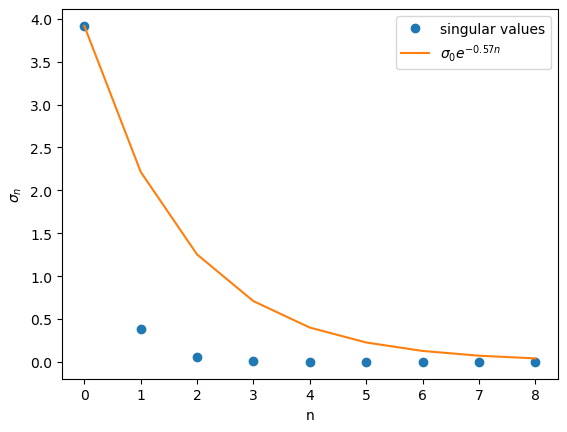

In [3]:
n_linspace = np.arange(0, len(sigma))
plt.plot(n_linspace, sigma, 'o', label ='singular values')
a = sigma[0]
b = -0.57
exp_fit = a * np.exp(b * n_linspace)
plt.plot(n_linspace, exp_fit, label = r'$\sigma_0 e^{-0.57 n}$')
plt.legend(loc = 'upper right')
plt.xlabel('n')
plt.ylabel(r'$\sigma_n$')
plt.savefig(f'sigma_Tmax_{Tmax}_Tmin_{Tmin}_ximin_{ximin}_ximax_{ximax}.png')